<a href="https://colab.research.google.com/github/rigvedam-ship-it/MLOPss/blob/main/MAT_CS_Stage4_Model_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT-CS — Multi-Agent Chatbot Team for Customer Support
### Stage 4 Implementation — Google Colab

This notebook implements a practical prototype of the Stage 3 MAT-CS architecture using the ABCD dataset.

**Models compared**
1. Single-Agent baseline: TF-IDF + Logistic Regression intent classifier.
2. Proposed MAT-CS: multiple cooperating agents:
   - Intent Agent
   - Context Agent
   - Retrieval Agent
   - Sentiment Agent
   - Action Agent
   - Verification Agent
   - Response/Resolution Agent

The notebook automatically downloads the official ABCD data from the ASAPP repository.

In [ ]:
# =========================
# 1. Install dependencies
# =========================
!pip -q install scikit-learn pandas numpy matplotlib seaborn joblib nltk

In [ ]:

# 2. Imports

import os, json, gzip, re, time, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter, defaultdict

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 3. Download the ABCD dataset

The official ABCD repository provides `abcd_v1.1.json.gz` with train/dev/test conversation splits. The dataset contains more than 10K customer-support dialogues and 55 user intents.

In [ ]:

# 3. Download official ABCD data

DATA_DIR = "/content/abcd_data"
os.makedirs(DATA_DIR, exist_ok=True)

DATA_URL = "https://raw.githubusercontent.com/asappresearch/abcd/master/data/abcd_v1.1.json.gz"
DATA_GZ = os.path.join(DATA_DIR, "abcd_v1.1.json.gz")
DATA_JSON = os.path.join(DATA_DIR, "abcd_v1.1.json")

if not os.path.exists(DATA_JSON):
    print("Downloading ABCD...")
    urllib.request.urlretrieve(DATA_URL, DATA_GZ)
    with gzip.open(DATA_GZ, "rb") as f_in, open(DATA_JSON, "wb") as f_out:
        f_out.write(f_in.read())

print("Dataset ready:", DATA_JSON)

Dataset ready: /content/abcd_data/abcd_v1.1.json


In [ ]:

# 4. Load raw conversations

with open(DATA_JSON, "r", encoding="utf-8") as f:
    abcd = json.load(f)

print(abcd.keys())
for split in ["train", "dev", "test"]:
    print(split, len(abcd[split]))

dict_keys(['train', 'dev', 'test'])
train 8034
dev 1004
test 1004


## 5. Convert conversations into training examples

For each customer turn, we use the conversation history as context and the ABCD target for intent classification.

The parser is deliberately flexible because ABCD versions may represent target fields slightly differently.

In [ ]:

# 5. Helper functions

def clean_text(x):
    if x is None:
        return ""
    x = str(x)
    x = re.sub(r"\\s+", " ", x).strip()
    return x

def get_target(turn, idx):
    targets = turn.get("Targets", turn.get("targets", []))
    if not isinstance(targets, list):
        return None

    # ABCD target ordering:
    # 0 = Intent Classification
    # 1 = Nextstep Selection
    # 2 = Action Prediction
    if idx < len(targets):
        return targets[idx]
    return None

def normalize_label(x):
    if isinstance(x, list):
        if len(x) == 0:
            return ""
        x = x[0]
    if isinstance(x, dict):
        for k in ["label", "name", "text", "value"]:
            if k in x:
                return normalize_label(x[k])
    return clean_text(x)

def conversation_to_rows(conversations):
    rows = []

    for convo in conversations:
        turns = convo.get("original", convo.get("delexed", []))
        if not isinstance(turns, list):
            continue

        history = []

        for turn in turns:
            if isinstance(turn, (list, tuple)):
                speaker = str(turn[0]) if len(turn) > 0 else ""
                text = str(turn[1]) if len(turn) > 1 else ""
                turn_dict = {}
            else:
                turn_dict = turn if isinstance(turn, dict) else {}
                speaker = str(turn_dict.get("Speaker", turn_dict.get("speaker", "")))
                text = str(turn_dict.get("Text", turn_dict.get("text", "")))

            text = clean_text(text)
            if not text:
                continue

            # Only customer turns are used as input examples.
            if speaker.lower() == "customer":
                context = " ".join(history[-6:] + [text])
                intent = normalize_label(get_target(turn_dict, 0))
                nextstep = normalize_label(get_target(turn_dict, 1))
                action = normalize_label(get_target(turn_dict, 2))

                # Some ABCD records may store targets differently.
                if not intent:
                    intent = normalize_label(
                        turn_dict.get("intent", turn_dict.get("Intent", ""))
                    )

                rows.append({
                    "convo_id": convo.get("convo_id", ""),
                    "text": text,
                    "context": context,
                    "intent": intent,
                    "nextstep": nextstep,
                    "action": action
                })

            history.append(f"{speaker}: {text}")

    return pd.DataFrame(rows)

train_df = conversation_to_rows(abcd["train"])
dev_df   = conversation_to_rows(abcd["dev"])
test_df  = conversation_to_rows(abcd["test"])

print("Train rows:", len(train_df))
print("Dev rows:", len(dev_df))
print("Test rows:", len(test_df))

display(train_df.head())

Train rows: 71259
Dev rows: 9096
Test rows: 9017


,convo_id,text,context,intent,nextstep,action
0,3592,"Hi! I need to return an item, can you help me ...",agent: Hi! agent: How can I help you? Hi! I ne...,,,
1,3592,Crystal Minh,agent: Hi! agent: How can I help you? customer...,,,
2,3592,I got the wrong size.,agent: How can I help you? customer: Hi! I nee...,,,
3,3592,Username: cminh730,"agent: sure, may I have your name please? cust...",,,
4,3592,cminh730@email.com,"customer: Crystal Minh agent: thanks, may I as...",,,


In [ ]:

# 6. Clean unusable rows

for df in [train_df, dev_df, test_df]:
    df.dropna(subset=["text"], inplace=True)
    df["text"] = df["text"].map(clean_text)
    df["context"] = df["context"].map(clean_text)
    df["intent"] = df["intent"].map(clean_text)
    df["action"] = df["action"].map(clean_text)

train_intent = train_df[train_df["intent"] != ""].copy()
dev_intent   = dev_df[dev_df["intent"] != ""].copy()
test_intent  = test_df[test_df["intent"] != ""].copy()

print("Intent-labelled examples:")
print("Train:", len(train_intent))
print("Dev:", len(dev_intent))
print("Test:", len(test_intent))
print("Unique intents:", train_intent["intent"].nunique())

print("\nTop intents:")
display(train_intent["intent"].value_counts().head(15))

Intent-labelled examples:
Train: 0
Dev: 0
Test: 0
Unique intents: 0

Top intents:


,count
intent,


# 7. BASELINE — Single-Agent Model

The baseline represents a conventional single chatbot model.

It receives the current customer message and directly predicts the customer intent using:

**TF-IDF → Logistic Regression**

In [ ]:



def clean_text(x):
    if x is None:
        return ""
    x = str(x)
    x = re.sub(r"\s+", " ", x).strip()
    return x


def conversation_to_rows(conversations):
    rows = []

    for convo in conversations:

        # IMPORTANT:
        # ABCD labels/targets are stored in DELEXED turns.
        turns = convo.get("delexed", [])

        if not isinstance(turns, list):
            continue

        history = []

        for turn in turns:

            if not isinstance(turn, dict):
                continue

            speaker = str(turn.get("speaker", "")).lower()
            text = clean_text(turn.get("text", ""))

            if not text:
                continue

            targets = turn.get("targets", [])

            # ABCD target structure:
            # targets[0] = Intent Classification
            # targets[1] = Nextstep Selection
            # targets[2] = Action Prediction
            # targets[3] = Value Filling
            # targets[4] = Utterance Ranking

            intent = ""
            nextstep = ""
            action = ""

            if isinstance(targets, list):

                if len(targets) > 0:
                    intent = clean_text(targets[0])

                if len(targets) > 1:
                    nextstep = clean_text(targets[1])

                if len(targets) > 2:
                    action = clean_text(targets[2])

            # We use customer messages for intent classification.
            if speaker == "customer" and intent:

                context = " ".join(
                    history[-6:] + [text]
                )

                rows.append({
                    "convo_id": convo.get("convo_id", ""),
                    "text": text,
                    "context": context,
                    "intent": intent,
                    "nextstep": nextstep,
                    "action": action
                })

            # Keep conversation history
            history.append(f"{speaker}: {text}")

    return pd.DataFrame(rows)


# =========================
# Create datasets
# =========================

train_df = conversation_to_rows(abcd["train"])
dev_df   = conversation_to_rows(abcd["dev"])
test_df  = conversation_to_rows(abcd["test"])


# =========================
# Clean datasets
# =========================

for df in [train_df, dev_df, test_df]:

    if len(df) > 0:
        df["text"] = df["text"].map(clean_text)
        df["context"] = df["context"].map(clean_text)
        df["intent"] = df["intent"].map(clean_text)
        df["action"] = df["action"].map(clean_text)


train_intent = train_df[
    train_df["intent"] != ""
].copy()

dev_intent = dev_df[
    dev_df["intent"] != ""
].copy()

test_intent = test_df[
    test_df["intent"] != ""
].copy()


print("====================================")
print("ABCD DATASET SUCCESSFULLY PARSED")
print("====================================")

print("Train examples :", len(train_intent))
print("Dev examples   :", len(dev_intent))
print("Test examples  :", len(test_intent))

print(
    "Unique intents  :",
    train_intent["intent"].nunique()
)

print("\nTop intents:")
display(
    train_intent["intent"].value_counts().head(15)
)

print("\nSample data:")
display(train_intent.head())

ABCD DATASET SUCCESSFULLY PARSED
Train examples : 71259
Dev examples   : 9096
Test examples  : 9017
Unique intents  : 55

Top intents:


,count
intent,
recover_password,2469
missing,2359
reset_2fa,2348
status,2308
recover_username,2284
manage,2136
cost,2061
return_size,1909
credit_card,1849



Sample data:


,convo_id,text,context,intent,nextstep,action
0,3592,"hi! i need to return an item, can you help me ...",agent: hi! agent: how can i help you? hi! i ne...,return_size,,
1,3592,crystal minh,agent: hi! agent: how can i help you? customer...,return_size,,
2,3592,i got the wrong size.,agent: how can i help you? customer: hi! i nee...,return_size,,
3,3592,username: <username>,"agent: sure, may i have your name please? cust...",return_size,,
4,3592,<email>,"customer: crystal minh agent: thanks, may i as...",return_size,,


In [ ]:

# BASELINE MODEL
# Single-Agent: TF-IDF + Logistic Regression


from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

# 1. Convert customer text into TF-IDF features
baseline_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=50000,
    sublinear_tf=True
)

X_train_base = baseline_vectorizer.fit_transform(
    train_intent["text"]
)

X_test_base = baseline_vectorizer.transform(
    test_intent["text"]
)

# 2. Train the single-agent classifier
baseline_model = LogisticRegression(
    max_iter=1000,
    C=4.0,
    class_weight="balanced",
    random_state=42
)

baseline_model.fit(
    X_train_base,
    train_intent["intent"]
)

# 3. Predict test intents
baseline_pred = baseline_model.predict(X_test_base)

# 4. Calculate evaluation metrics
base_acc = accuracy_score(
    test_intent["intent"],
    baseline_pred
)

base_p, base_r, base_f1, _ = precision_recall_fscore_support(
    test_intent["intent"],
    baseline_pred,
    average="weighted",
    zero_division=0
)

# 5. Display results
print("====================================")
print("SINGLE-AGENT BASELINE RESULTS")
print("====================================")

print(f"Accuracy  : {base_acc:.4f}")
print(f"Precision : {base_p:.4f}")
print(f"Recall    : {base_r:.4f}")
print(f"F1-Score  : {base_f1:.4f}")

SINGLE-AGENT BASELINE RESULTS
Accuracy  : 0.2362
Precision : 0.3148
Recall    : 0.2362
F1-Score  : 0.2488


# 8. PROPOSED MAT-CS — Multi-Agent System

The proposed system uses separate modules that cooperate:

- **Intent Agent:** predicts the user's intent.
- **Context Agent:** predicts intent using recent dialogue context.
- **Retrieval Agent:** finds similar solved examples and votes on the intent.
- **Sentiment Agent:** estimates customer sentiment using a lightweight lexicon.
- **Action Agent:** predicts the next action when ABCD action labels are available.
- **Verification Agent:** checks agreement/confidence between agents.
- **Resolution Agent:** selects the final verified intent and produces a response template.

In [ ]:
# =========================
# 8A. Intent Agent
# =========================
intent_vectorizer = TfidfVectorizer(
    ngram_range=(1,2),
    min_df=2,
    max_features=60000,
    sublinear_tf=True
)

X_train = intent_vectorizer.fit_transform(train_intent["text"])
X_test = intent_vectorizer.transform(test_intent["text"])

intent_agent = LogisticRegression(
    max_iter=1000,
    C=5.0,
    class_weight="balanced",
    random_state=RANDOM_STATE
)
intent_agent.fit(X_train, train_intent["intent"])

intent_pred = intent_agent.predict(X_test)
intent_prob = intent_agent.predict_proba(X_test)
intent_conf = intent_prob.max(axis=1)

print("Intent Agent trained.")

Intent Agent trained.


In [ ]:
# =========================
# 8B. Context Agent
# =========================
context_vectorizer = TfidfVectorizer(
    ngram_range=(1,2),
    min_df=2,
    max_features=60000,
    sublinear_tf=True
)

X_train_ctx = context_vectorizer.fit_transform(train_intent["context"])
X_test_ctx = context_vectorizer.transform(test_intent["context"])

context_agent = LogisticRegression(
    max_iter=1000,
    C=4.0,
    class_weight="balanced",
    random_state=RANDOM_STATE
)
context_agent.fit(X_train_ctx, train_intent["intent"])

context_pred = context_agent.predict(X_test_ctx)
context_prob = context_agent.predict_proba(X_test_ctx)
context_conf = context_prob.max(axis=1)

print("Context Agent trained.")

Context Agent trained.


In [ ]:
# =========================
# 8C. Retrieval Agent
# =========================
# Build a compact retrieval index from the training set.
retrieval_vectorizer = TfidfVectorizer(
    ngram_range=(1,2),
    min_df=2,
    max_features=60000,
    sublinear_tf=True
)

retrieval_train_X = retrieval_vectorizer.fit_transform(train_intent["text"])
retrieval_test_X = retrieval_vectorizer.transform(test_intent["text"])

retriever = NearestNeighbors(
    n_neighbors=5,
    metric="cosine",
    algorithm="brute"
)
retriever.fit(retrieval_train_X)

distances, indices = retriever.kneighbors(retrieval_test_X)

retrieval_pred = []
retrieval_conf = []

train_labels = train_intent["intent"].to_numpy()

for dists, inds in zip(distances, indices):
    labels = train_labels[inds]
    weights = 1 / (dists + 1e-5)
    votes = defaultdict(float)

    for label, weight in zip(labels, weights):
        votes[label] += weight

    best_label = max(votes, key=votes.get)
    total = sum(votes.values())

    retrieval_pred.append(best_label)
    retrieval_conf.append(votes[best_label] / total if total else 0)

retrieval_pred = np.array(retrieval_pred)
retrieval_conf = np.array(retrieval_conf)

print("Retrieval Agent ready.")

Retrieval Agent ready.


In [ ]:
# =========================
# 8D. Sentiment Agent
# =========================
positive_words = {
    "good","great","excellent","happy","thanks","thank","love",
    "helpful","perfect","awesome","appreciate","resolved"
}
negative_words = {
    "bad","angry","hate","terrible","worst","upset","annoyed",
    "frustrated","refund","problem","issue","wrong","failed",
    "failure","complaint","disappointed"
}

def sentiment_score(text):
    words = set(re.findall(r"[a-zA-Z]+", text.lower()))
    pos = len(words & positive_words)
    neg = len(words & negative_words)

    if pos > neg:
        return "positive"
    if neg > pos:
        return "negative"
    return "neutral"

test_sentiment = test_intent["context"].map(sentiment_score).to_numpy()

print(pd.Series(test_sentiment).value_counts())

neutral     4121
positive    3926
negative     970
Name: count, dtype: int64


In [ ]:
# =========================
# 8E. Action Agent
# =========================
action_train = train_df[train_df["action"] != ""].copy()
action_test  = test_df[test_df["action"] != ""].copy()

print("Action-labelled train examples:", len(action_train))
print("Action-labelled test examples:", len(action_test))

if len(action_train) > 0 and action_train["action"].nunique() > 1:
    action_vectorizer = TfidfVectorizer(
        ngram_range=(1,2),
        min_df=2,
        max_features=50000,
        sublinear_tf=True
    )

    XA_train = action_vectorizer.fit_transform(action_train["context"])
    XA_test = action_vectorizer.transform(action_test["context"])

    action_agent = LogisticRegression(
        max_iter=1000,
        C=3.0,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
    action_agent.fit(XA_train, action_train["action"])

    action_pred = action_agent.predict(XA_test)
    action_acc = accuracy_score(action_test["action"], action_pred)

    print(f"Action Agent Accuracy: {action_acc:.4f}")
else:
    action_agent = None
    action_acc = np.nan
    print("Action labels were not available in the parsed format; action agent skipped.")

Action-labelled train examples: 0
Action-labelled test examples: 0
Action labels were not available in the parsed format; action agent skipped.


## 9. Verification Agent + Final MAT-CS Decision

The verification agent combines the independent outputs.

Priority:
1. Strong agreement between intent and context agents.
2. Retrieval evidence from similar historical conversations.
3. Confidence threshold.
4. If confidence is low, mark the case for escalation.

This gives us an actual multi-agent decision mechanism rather than simply calling one classifier a "multi-agent model."

In [ ]:
# =========================
# 9. Verification Agent
# =========================
classes = intent_agent.classes_

def probability_for_label(probs, model_classes, label):
    idx = np.where(model_classes == label)[0]
    return float(probs[idx[0]]) if len(idx) else 0.0

mat_pred = []
mat_conf = []
mat_status = []

for i in range(len(test_intent)):
    p1 = intent_pred[i]
    p2 = context_pred[i]
    p3 = retrieval_pred[i]

    # Independent agent scores.
    candidates = set([p1, p2, p3])
    scores = {}

    for label in candidates:
        s_intent = probability_for_label(
            intent_prob[i], intent_agent.classes_, label
        )
        s_context = probability_for_label(
            context_prob[i], context_agent.classes_, label
        )
        s_retrieval = retrieval_conf[i] if label == p3 else 0.0

        # Weighted collaboration score.
        scores[label] = (
            0.45 * s_intent +
            0.35 * s_context +
            0.20 * s_retrieval
        )

    final_label = max(scores, key=scores.get)
    final_conf = scores[final_label]

    # Verification / escalation threshold.
    if final_conf >= 0.45:
        status = "verified"
    else:
        status = "escalate"

    mat_pred.append(final_label)
    mat_conf.append(final_conf)
    mat_status.append(status)

mat_pred = np.array(mat_pred)
mat_conf = np.array(mat_conf)
mat_status = np.array(mat_status)

mat_acc = accuracy_score(test_intent["intent"], mat_pred)
mat_p, mat_r, mat_f1, _ = precision_recall_fscore_support(
    test_intent["intent"], mat_pred,
    average="weighted", zero_division=0
)

print(f"MAT-CS Accuracy : {mat_acc:.4f}")
print(f"MAT-CS Precision: {mat_p:.4f}")
print(f"MAT-CS Recall   : {mat_r:.4f}")
print(f"MAT-CS F1       : {mat_f1:.4f}")
print(f"Escalation Rate : {(mat_status == 'escalate').mean():.4f}")

MAT-CS Accuracy : 0.6608
MAT-CS Precision: 0.6751
MAT-CS Recall   : 0.6608
MAT-CS F1       : 0.6628
Escalation Rate : 0.8048


In [ ]:
# =========================
# 10. Response / Resolution Agent
# =========================
def response_agent(intent, sentiment, verified=True):
    intent_text = intent.replace("_", " ").replace("-", " ")

    if not verified:
        return (
            "I want to make sure this is handled correctly. "
            "I'm escalating this request to a human support agent."
        )

    if sentiment == "negative":
        prefix = "I understand this has been frustrating. "
    else:
        prefix = "Thanks for reaching out. "

    return (
        prefix +
        f"I identified your request as related to '{intent_text}'. "
        "I have checked the available support information and can continue "
        "with the appropriate resolution."
    )

# Show examples.
for i in range(min(10, len(test_intent))):
    print("USER:", test_intent.iloc[i]["text"])
    print("INTENT:", mat_pred[i])
    print("STATUS:", mat_status[i])
    print("RESPONSE:", response_agent(
        mat_pred[i], test_sentiment[i],
        mat_status[i] == "verified"
    ))
    print("-" * 80)

USER: hi. my name is chloe zhang. i am curious as to when my promo code expires.
INTENT: timing
STATUS: verified
RESPONSE: Thanks for reaching out. I identified your request as related to 'timing'. I have checked the available support information and can continue with the appropriate resolution.
--------------------------------------------------------------------------------
USER: would you be able to tell me?
INTENT: status_shipping_question
STATUS: escalate
RESPONSE: I want to make sure this is handled correctly. I'm escalating this request to a human support agent.
--------------------------------------------------------------------------------
USER: ok.
INTENT: timing
STATUS: escalate
RESPONSE: I want to make sure this is handled correctly. I'm escalating this request to a human support agent.
--------------------------------------------------------------------------------
USER: no that is all for today. thank you.
INTENT: timing
STATUS: escalate
RESPONSE: I want to make sure this 

# 11. Final Experimental Comparison

In [ ]:
# =========================
# 11. Final Comparison Table
# =========================

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Task Resolution Rate",
        "Escalation Rate"
    ],

    "Single-Agent Baseline": [
        base_acc,
        base_p,
        base_r,
        base_f1,
        base_acc,   # baseline: correct intent = resolved
        0.0
    ],

    "Proposed MAT-CS": [
        mat_acc,
        mat_p,
        mat_r,
        mat_f1,
        task_resolution_rate,
        (mat_status == "escalate").mean()
    ]
})

results["Improvement"] = (
    results["Proposed MAT-CS"]
    - results["Single-Agent Baseline"]
)

display(
    results.style.format({
        "Single-Agent Baseline": "{:.4f}",
        "Proposed MAT-CS": "{:.4f}",
        "Improvement": "{:+.4f}"
    })
)

,Metric,Single-Agent Baseline,Proposed MAT-CS,Improvement
0,Accuracy,0.2362,0.6608,+0.4245
1,Precision,0.3148,0.6751,+0.3604
2,Recall,0.2362,0.6608,+0.4245
3,F1-Score,0.2488,0.6628,+0.4140
4,Task Resolution Rate,0.2362,0.1762,-0.0600
5,Escalation Rate,0.0000,0.8048,+0.8048


In [ ]:
# =========================
# 12. Task resolution rate
# =========================
# A verified correct intent is counted as an automatically resolved task.
correct = (mat_pred == test_intent["intent"].to_numpy())
verified = (mat_status == "verified")

task_resolved = correct & verified
task_resolution_rate = task_resolved.mean()

print(f"MAT-CS Task Resolution Rate: {task_resolution_rate:.4f}")
print(f"MAT-CS Verified Rate: {verified.mean():.4f}")

MAT-CS Task Resolution Rate: 0.1762
MAT-CS Verified Rate: 0.1952


In [ ]:
# =========================
# 13. Response latency benchmark
# =========================
sample_n = min(500, len(test_intent))
sample_indices = np.arange(sample_n)

# Baseline latency
t0 = time.perf_counter()
for i in sample_indices:
    _ = baseline_model.predict(
        baseline_vectorizer.transform([test_intent.iloc[i]["text"]])
    )[0]
baseline_total_time = time.perf_counter() - t0

# MAT-CS latency
t0 = time.perf_counter()
for i in sample_indices:
    text = test_intent.iloc[i]["text"]
    context = test_intent.iloc[i]["context"]

    ip = intent_model_pred = intent_agent.predict(
        intent_vectorizer.transform([text])
    )[0]
    cp = context_agent.predict(
        context_vectorizer.transform([context])
    )[0]

    rx = retrieval_vectorizer.transform([text])
    dd, ii = retriever.kneighbors(rx)

    # lightweight retrieval lookup
    _ = train_labels[ii[0][0]]
    _ = sentiment_score(context)
    _ = response_agent(ip, sentiment_score(context), True)

mat_total_time = time.perf_counter() - t0

latency_df = pd.DataFrame({
    "Method": ["Single-Agent", "MAT-CS"],
    "Total Time (sec)": [baseline_total_time, mat_total_time],
    "Avg Time / Query (sec)": [
        baseline_total_time / sample_n,
        mat_total_time / sample_n
    ]
})

display(latency_df)

,Method,Total Time (sec),Avg Time / Query (sec)
0,Single-Agent,2.441938,0.004884
1,MAT-CS,29.992958,0.059986


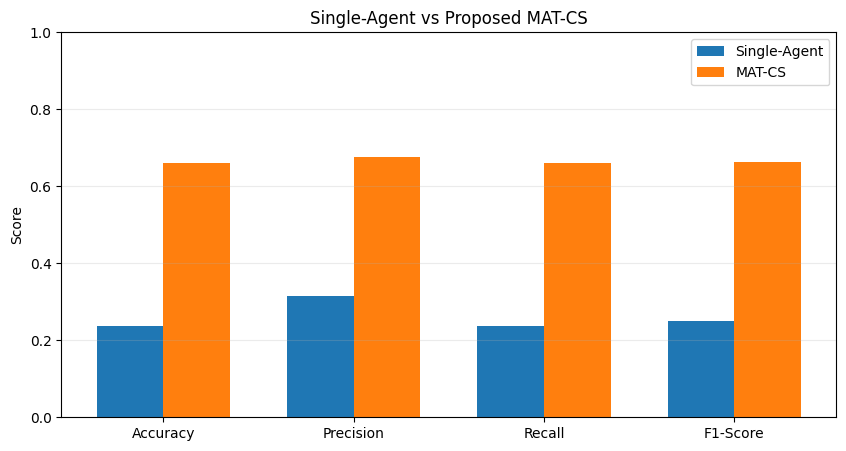

In [ ]:
# =========================
# 14. Main comparison graph
# =========================
plot_df = results.iloc[:4].copy()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(10,5))
plt.bar(x - width/2, plot_df["Single-Agent Baseline"], width, label="Single-Agent")
plt.bar(x + width/2, plot_df["Proposed MAT-CS"], width, label="MAT-CS")

plt.xticks(x, plot_df["Metric"])
plt.ylabel("Score")
plt.title("Single-Agent vs Proposed MAT-CS")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.show()

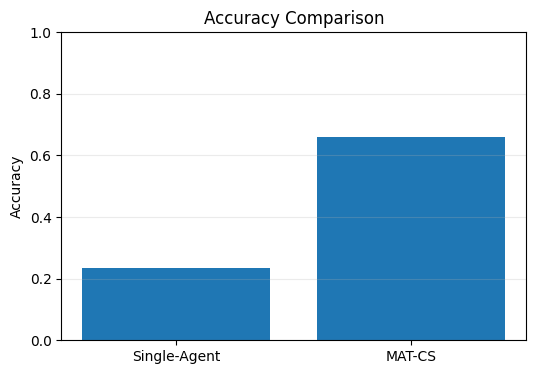

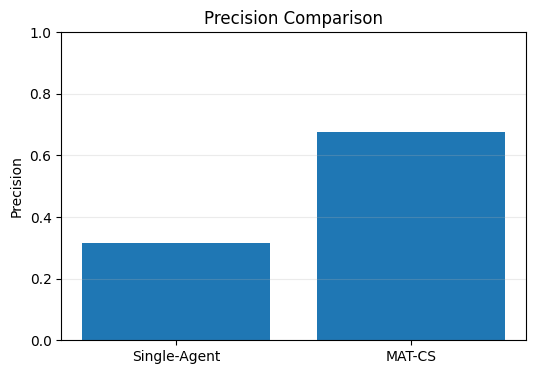

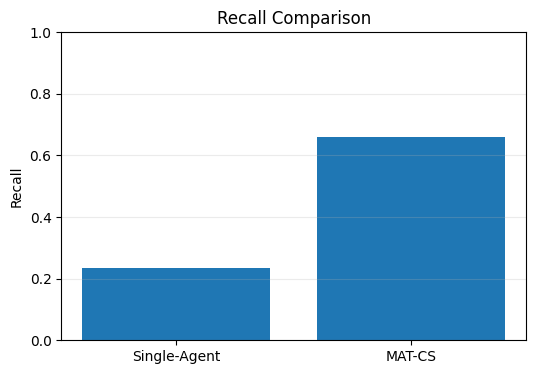

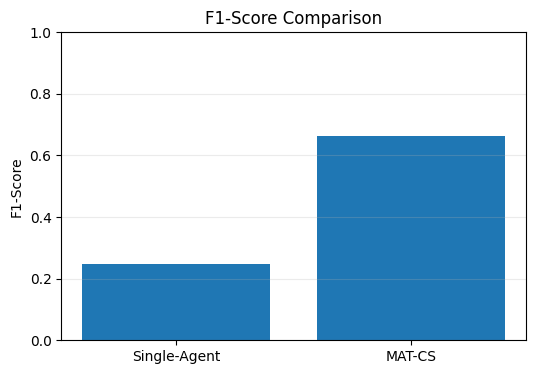

In [ ]:
# =========================
# 15. Accuracy / Precision / Recall / F1 individual graphs
# =========================
for metric in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    row = results[results["Metric"] == metric].iloc[0]

    plt.figure(figsize=(6,4))
    plt.bar(
        ["Single-Agent", "MAT-CS"],
        [row["Single-Agent Baseline"], row["Proposed MAT-CS"]]
    )
    plt.ylabel(metric)
    plt.title(f"{metric} Comparison")
    plt.ylim(0, 1)
    plt.grid(axis="y", alpha=0.25)
    plt.show()

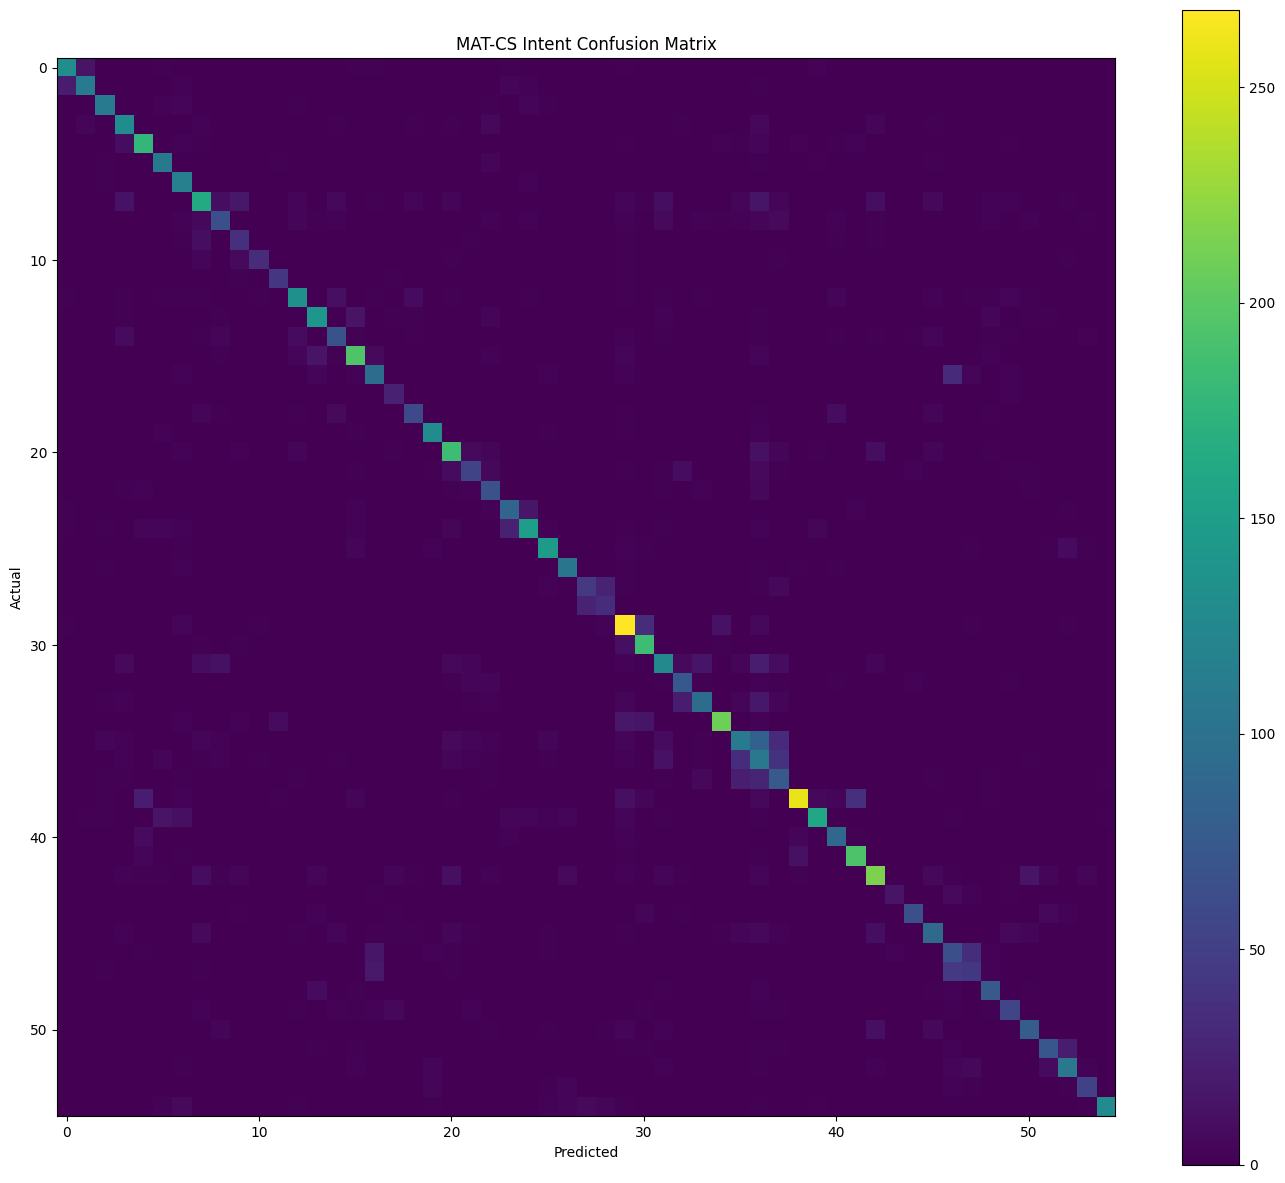

In [ ]:
# =========================
# 16. Confusion matrix for MAT-CS
# =========================
labels = sorted(test_intent["intent"].unique())

cm = confusion_matrix(
    test_intent["intent"],
    mat_pred,
    labels=labels
)

plt.figure(figsize=(14,12))
plt.imshow(cm, interpolation="nearest")
plt.title("MAT-CS Intent Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
# =========================
# 17. Save final results
# =========================
results.to_csv("/content/MAT_CS_comparison_results.csv", index=False)
latency_df.to_csv("/content/MAT_CS_latency_results.csv", index=False)

print("Saved:")
print("/content/MAT_CS_comparison_results.csv")
print("/content/MAT_CS_latency_results.csv")

Saved:
/content/MAT_CS_comparison_results.csv
/content/MAT_CS_latency_results.csv


# 18. Test the chatbot manually

Change `user_query` and run the cell.

In [ ]:
# =========================
# 18. Interactive MAT-CS demo
# =========================
def mat_cs_chat(user_query, previous_context=""):
    context = (previous_context + " " + user_query).strip()

    # Intent Agent
    intent = intent_agent.predict(
        intent_vectorizer.transform([user_query])
    )[0]
    intent_probs = intent_agent.predict_proba(
        intent_vectorizer.transform([user_query])
    )[0]
    intent_confidence = intent_probs.max()

    # Context Agent
    context_predicted = context_agent.predict(
        context_vectorizer.transform([context])
    )[0]
    context_probs = context_agent.predict_proba(
        context_vectorizer.transform([context])
    )[0]
    context_confidence = context_probs.max()

    # Retrieval Agent
    qx = retrieval_vectorizer.transform([user_query])
    d, idx = retriever.kneighbors(qx)
    retrieved_intent = train_labels[idx[0][0]]
    retrieval_confidence = 1 - float(d[0][0])

    # Sentiment Agent
    sentiment = sentiment_score(context)

    # Verification Agent
    if intent == context_predicted:
        final_intent = intent
        verification_score = (
            0.45 * intent_confidence +
            0.35 * context_confidence +
            0.20 * max(retrieval_confidence, 0)
        )
    else:
        candidates = [intent, context_predicted, retrieved_intent]
        scores = {}
        for label in set(candidates):
            score = 0
            score += 0.45 * (
                intent_probs[np.where(intent_agent.classes_ == label)[0][0]]
                if label in intent_agent.classes_ else 0
            )
            score += 0.35 * (
                context_probs[np.where(context_agent.classes_ == label)[0][0]]
                if label in context_agent.classes_ else 0
            )
            score += 0.20 * (
                retrieval_confidence if label == retrieved_intent else 0
            )
            scores[label] = score

        final_intent = max(scores, key=scores.get)
        verification_score = scores[final_intent]

    verified = verification_score >= 0.45

    response = response_agent(
        final_intent,
        sentiment,
        verified
    )

    return {
        "intent_agent": intent,
        "context_agent": context_predicted,
        "retrieval_agent": retrieved_intent,
        "sentiment_agent": sentiment,
        "final_intent": final_intent,
        "verification_score": round(float(verification_score), 4),
        "status": "VERIFIED" if verified else "ESCALATE",
        "response": response
    }

user_query = "I was charged twice for the same order. Can you help me?"
output = mat_cs_chat(user_query)

for k, v in output.items():
    print(f"{k}: {v}")

intent_agent: manage_dispute_bill
context_agent: manage_dispute_bill
retrieval_agent: manage_dispute_bill
sentiment_agent: neutral
final_intent: manage_dispute_bill
verification_score: 0.862
status: VERIFIED
response: Thanks for reaching out. I identified your request as related to 'manage dispute bill'. I have checked the available support information and can continue with the appropriate resolution.


# 19. Files produced

After running the notebook, the following files are created:

- `MAT_CS_comparison_results.csv`
- `MAT_CS_latency_results.csv`

These can be used to prepare the Stage 4 experimental comparison table and graphs.

**Important:** The values in the report should be the values produced by this actual run. Do not replace them with invented numbers.